# 03 · Modelos supervisados

**Grupo:** Oscar Romero Quincoces · Fernando Dapena Tauste · Daniel Garcia Lopez

**Objetivo.** El 02 midió hasta dónde llega la detección de anomalías pura, que aprende solo lo normal. Aquí usamos lo que el 02 dejó fuera: las **206 etiquetas de fraude de train**. Un clasificador no pregunta "¿es rara esta transacción?", sino "¿se parece a los fraudes que ya hemos visto?". El profesor lo planteó así: con etiquetas, supervisado y no supervisado se acercan, y lo que decide es **el tipo de anomalía** [03:46:00]–[03:47:11]. Hay que medirlo.

**Referencia a batir (02, D-2.4):** GMM 5 · 1 eje menor, **0,779 ± 0,060 en CV** y 0,736 en test. Pistas del 02: el eje menor de los normales concentra la señal (D-2.2), y ~1/6 de los fraudes caen dentro de la nube normal, donde ningún detector de rareza los ve (02 §11, §13). Es lo que el supervisado tiene que recuperar.

El 03 deja tres cosas: el **mejor clasificador supervisado** y su configuración, la respuesta a si compensa **tratar el desbalanceo**, y sus **scores** (OOF en train, test y producción) para el híbrido del 04.

**Cómo leer este notebook.** Como el 01 y el 02: cada sección sigue el orden **pregunta → resultado → conclusión → impacto**, y todos los modelos se comparan con el mismo protocolo (§1).

| Parte I · Modelos | Parte II · Comparación y entrega |
|---|---|
| 0. Setup | 7. ¿Qué modelo gana en CV? |
| 1. ¿Qué hay que batir y cómo se compara? | 8. ¿Ve los fraudes que el 02 no veía? |
| 2. ¿Basta un modelo lineal? | 9. ¿Se confirma en test? |
| 3. ¿Y con árboles? | 10. ¿En qué se fija el modelo? |
| 4. ¿Por qué LightGBM por defecto se hunde? | 11. Exportar scores para el 04 |
| 5. ¿Hay que tratar el desbalanceo? | 12. Conclusiones |
| 6. ¿Qué variables y qué hiperparámetros? | Conectores |

In [3]:
# ============================================================
# CELDA COMÚN v2 — NO MODIFICAR (idéntica en 02, 03, 04 y 99)
# Lee el dataset preparado en 01: split fijo, folds por grupo y features. Ver D-0.1, D-1.1–D-1.4.
# Uso: m = fit(modelo, X_train, y_train); report("x", score(m, X_test)); cv_aupr(modelo); save_submission(score(m, X_prod))
# ============================================================
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone, is_classifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

pd.options.display.max_columns = None
SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = ROOT / "data" / "output"
PREP_CSV = Path(os.environ.get("PREP_CSV", OUTPUT_DIR / "01_dataset_preparado.csv"))
if not PREP_CSV.exists():
    raise FileNotFoundError(f"No existe {PREP_CSV}: ejecuta antes notebooks/01_EDA_y_preprocesado.ipynb")

FEAT_RAW = [f"X{i}" for i in range(1, 21)] + ["Amount"]
df = pd.read_csv(PREP_CSV)
df[FEAT_RAW] = df[FEAT_RAW].astype(float)  # el CSV guarda X enteras: se leen como float, igual que los originales
df_const = df[df["split"] != "prod"].sort_values("row_id").reset_index(drop=True)
df_prod = df[df["split"] == "prod"].sort_values("row_id").reset_index(drop=True)
FEATURES = [f"X{i}" for i in range(1, 21)] + ["log1p_Amount", "amount_freq"]  # conjunto por defecto (D-1.2)

tr, te = df_const[df_const["split"] == "train"], df_const[df_const["split"] == "test"]
X_train, y_train, groups_train = tr[FEATURES], tr["Class"].astype(int), tr["group_id"]
X_test, y_test = te[FEATURES], te["Class"].astype(int)
X_prod = df_prod[FEATURES]
dup_test = te["dup_en_train"].to_numpy(bool)  # filas de test con copia exacta en train (D-1.1)
# Folds por grupo hechos en 01 → (idx_train, idx_val) posicionales sobre X_train; vale como cv= en sklearn
cv_splits = [(np.flatnonzero(tr["fold"].to_numpy() != k), np.flatnonzero(tr["fold"].to_numpy() == k)) for k in range(5)]

def make_pipe(model, scaler="standard"):
    """Escalador ('standard' | 'robust' | None) + modelo: el escalado se ajusta DENTRO de cada fold."""
    steps = {"standard": [StandardScaler()], "robust": [RobustScaler()], None: []}[scaler]
    return make_pipeline(*steps, model)

def score(model, X):
    """Mayor = más fraude. Clasificador: predict_proba[:, 1] (o decision_function). No supervisado: −score_samples."""
    if not is_classifier(model):
        return -model.score_samples(X)  # GMM: −log-verosimilitud; IF / OCSVM / LOF(novelty=True): −normalidad
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def fit(model, X, y):
    """Copia limpia ajustada: clasificador con (X, y); no supervisado SOLO con las normales (y == 0)."""
    y = np.asarray(y)
    return clone(model).fit(X, y) if is_classifier(model) else clone(model).fit(X[y == 0])

def metrics(y_true, scores):
    """Métrica oficial: AUPR (average_precision_score). Mayor score = más fraude."""
    return {"aupr": average_precision_score(y_true, scores), "roc_auc": roc_auc_score(y_true, scores)}

def cv_aupr(model, X=X_train, y=y_train):
    """AUPR por fold sobre cv_splits (clasificadores y no supervisados). Devuelve (media, std, scores OOF alineados con X)."""
    X, y, oof, auprs = np.asarray(X, dtype=float), np.asarray(y), np.zeros(len(y)), []
    assert len(X) == len(tr), "X debe tener las filas de X_train en su orden"
    for it, iv in cv_splits:
        oof[iv] = score(fit(model, X[it], y[it]), X[iv])
        auprs.append(average_precision_score(y[iv], oof[iv]))
    print(f"CV AUPR = {np.mean(auprs):.4f} ± {np.std(auprs):.4f}")
    return np.mean(auprs), np.std(auprs), oof

def report(name, s_test):
    """AUPR de test con y sin las filas duplicadas de train (D-1.1), y ROC-AUC."""
    s, y = np.asarray(s_test, dtype=float), y_test.to_numpy()
    assert len(s) == len(y), f"{len(s)} scores != {len(y)} filas de test"
    r = {"modelo": name, **metrics(y, s), "aupr_sin_dup": average_precision_score(y[~dup_test], s[~dup_test])}
    print(f"{name}: AUPR test={r['aupr']:.4f} | sin dup={r['aupr_sin_dup']:.4f} | ROC-AUC={r['roc_auc']:.4f}")
    return r

def plot_pr(y_true, scores_by_model, ax=None):
    ax = ax or plt.subplots(figsize=(6, 5))[1]
    for name, s in scores_by_model.items():
        p, r, _ = precision_recall_curve(y_true, s)
        ax.plot(r, p, label=f"{name} (AUPR={average_precision_score(y_true, s):.3f})")
    ax.axhline(np.mean(y_true), ls="--", c="grey", label="aleatorio")
    ax.set(xlabel="Recall", ylabel="Precision", title="Curva Precision-Recall")
    ax.legend()
    return ax

def save_submission(scores, name="scores_produccion"):
    """Entregable: CSV de UNA columna `score`, una fila por transacción de producción (mismo orden)."""
    scores = np.asarray(scores, dtype=float).ravel()
    assert len(scores) == len(df_prod) == 113_923, f"{len(scores)} scores, {len(df_prod)} filas de producción"
    assert np.isfinite(scores).all(), "hay scores no finitos"
    pd.DataFrame({"score": scores}).to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

print(f"train {X_train.shape} fraudes={y_train.sum()} | test {X_test.shape} fraudes={y_test.sum()} "
      f"(dup={dup_test.sum()}) | prod {X_prod.shape} | folds={[len(v) for _, v in cv_splits]}")

train (119618, 22) fraudes=206 | test (51266, 22) fraudes=89 (dup=1643) | prod (113923, 22) | folds=[23924, 23924, 23923, 23924, 23923]


## 0. Setup

Librerías y utilidades propias de este notebook. Los datos (`X_train`, `X_test`, `X_prod`, `cv_splits`) y las funciones `fit()`, `score()`, `make_pipe()`, `report()` y `plot_pr()` vienen de la celda común v2.

In [4]:
import time
import warnings
import contextlib, io
import seaborn as sns
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.mixture import GaussianMixture
import xgboost as xgb
import lightgbm as lgb
from imblearn.pipeline import make_pipeline as imb_pipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook", rc={"figure.figsize": (8, 4.5), "axes.titleweight": "bold"})
C = {0: "#9e9e9e", 1: "#d62728"}          # gris = normal, rojo = fraude (como en 01 y 02)
LBL = {0: "normal", 1: "fraude"}
FAM = {"no supervisado": "#dd8452", "lineal": "#4c72b0", "bagging": "#55a868", "boosting": "#8172b3",
       "red neuronal": "#937860", "desbalanceo": "#da8bc3"}
N_JOBS = os.cpu_count() or 2

`evaluar()` es el **protocolo común** (§1), el mismo del 02: los 5 folds de `cv_splits`, ajuste con `fit()` de la celda común (los clasificadores ven normales **y** fraudes del fold de train; los no supervisados, solo normales) y AUPR en el fold de validación. Guarda la AUPR de cada fold (para comparar por pares) y los scores *out-of-fold* (para §8 y para el 04).

In [5]:
RES, OOF = {}, {}       # nombre → métricas de CV · nombre → scores out-of-fold alineados con X_train

def evaluar(nombre, model, familia, feats=FEATURES, guardar=True, verbose=True):
    # CV de 5 folds (cv_splits) con fit()/score() de la celda común: AUPR por fold y scores OOF.
    X, y = X_train[feats].to_numpy(float), y_train.to_numpy()
    t0, oof = time.time(), np.zeros(len(y))
    for it, iv in cv_splits:
        oof[iv] = score(fit(model, X[it], y[it]), X[iv])
    auprs = [average_precision_score(y[iv], oof[iv]) for _, iv in cv_splits]
    r = {"familia": familia, "n_feats": len(feats), "media": np.mean(auprs), "std": np.std(auprs),
         "segundos": time.time() - t0, **{f"fold{k}": a for k, a in enumerate(auprs)}}
    if guardar:
        RES[nombre], OOF[nombre] = r, oof
    if verbose:
        print(f"{nombre}: CV AUPR = {r['media']:.3f} ± {r['std']:.3f}  ({r['segundos']:.0f} s)")
    return r

def tabla_cv(nombres=None):
    # Resultados de CV ordenados por AUPR media.
    t = pd.DataFrame(RES).T.loc[nombres or list(RES)]
    return t.astype({c: float for c in t.columns if c != "familia"}).sort_values("media", ascending=False).round(3)

por_fold = lambda n: np.array([RES[n][f"fold{k}"] for k in range(5)])

def frente_a(nombres, ref):
    # Diferencia por pares con `ref`: media, peor y mejor fold, y en cuántos de los 5 folds gana.
    return pd.DataFrame({n: {"media": RES[n]["media"], "std": RES[n]["std"], f"dif. con {ref}": (por_fold(n) - por_fold(ref)).mean(),
                             "peor fold": (por_fold(n) - por_fold(ref)).min(), "folds que gana (de 5)": int((por_fold(n) > por_fold(ref)).sum())}
                         for n in nombres}).T.astype(float).round(3).astype({"folds que gana (de 5)": int})

La figura de comparación fold a fold del 02 (`plot_folds`) y el transformador `EjesPropios` (02 §6), que proyecta sobre los ejes de menor varianza de los **normales**. Aquí recibe también `y`: dentro de un clasificador, los ejes se calculan solo con los normales del fold de train, igual que en el 02.

In [6]:
def plot_folds(nombres, title="AUPR por fold (líneas = mismo fold; punto = media ± std)", ax=None):
    # Cada línea gris une el mismo fold en todos los modelos: si las líneas se cruzan, la diferencia no es robusta.
    t = tabla_cv(nombres).loc[nombres]
    ax = ax or plt.subplots(figsize=(max(6, 1.1 * len(nombres)), 4.5))[1]
    folds = t[[f"fold{k}" for k in range(5)]].to_numpy(float)
    x = np.arange(len(nombres))
    for k in range(5):
        ax.plot(x, folds[:, k], c="grey", lw=.8, alpha=.6, marker=".", zorder=1)
    for i, (n, r) in enumerate(t.iterrows()):
        ax.errorbar(i, r["media"], yerr=r["std"], fmt="o", ms=9, capsize=5, c=FAM[r["familia"]], zorder=2)
        ax.annotate(f"{r['media']:.3f}", (i, r["media"]), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_xticks(x, nombres, rotation=20, ha="right")
    ax.set(ylabel="AUPR (CV)", title=title)
    return ax

class EjesPropios(TransformerMixin, BaseEstimator):
    # Coordenadas en los k ejes de menor varianza de los normales estandarizados (02 §6).
    # Con y, los ejes se calculan solo con las filas y == 0. con_originales=True: las añade a las variables originales.
    def __init__(self, k=1, con_originales=False):
        self.k, self.con_originales = k, con_originales
    def fit(self, X, y=None):
        X0 = X if y is None else X[np.asarray(y) == 0]
        self.sc_ = StandardScaler().fit(X0)
        self.V_ = np.linalg.eigh(np.cov(self.sc_.transform(X0).T))[1][:, :self.k]    # autovalores en orden creciente
        return self
    def transform(self, X):
        Z = self.sc_.transform(X) @ self.V_
        return np.c_[X, Z] if self.con_originales else Z

---
# PARTE I · MODELOS

Primero la referencia y las reglas de comparación (§1). Después, de menos a más flexible: lineal (§2), árboles (§3–§4), el desbalanceo (§5) y el ajuste fino del mejor (§6).

## 1. ¿Qué hay que batir y cómo se compara?

**Qué miramos y por qué.** El protocolo es el del 02 §1, con un cambio: los clasificadores se ajustan con **todas** las filas del fold de train, fraudes incluidos (~165 por fold). Los fraudes de validación siguen sin verse nunca al ajustar. Las reglas para decidir no cambian:

1. **AUPR** (`average_precision_score`) en cada uno de los 5 folds `StratifiedGroupKFold` del 01. El aleatorio es **0,0017**.
2. Una diferencia de medias menor que ~1 std entre folds (≈ 0,06–0,08) **no es concluyente**, salvo que se repita en al menos **4 de los 5 folds** (02 §1).
3. El **test fijo** (89 fraudes) no se toca hasta §9, y se usa una sola vez.

La referencia se reevalúa aquí con el mismo `evaluar()` para tener sus AUPR por fold y sus scores OOF: el **GMM 5 · 1 eje menor** del 02 (RobustScaler + GMM 5 `full` sobre la coordenada en el eje menor).

In [7]:
GMM_EJE = make_pipeline(EjesPropios(1), make_pipe(GaussianMixture(5, random_state=SEED), "robust"))
REF = "GMM 5 · 1 eje menor (02)"
evaluar(REF, GMM_EJE, "no supervisado");

GMM 5 · 1 eje menor (02): CV AUPR = 0.779 ± 0.060  (3 s)


> **Conclusión:** la referencia se reproduce exacta, **0,779 ± 0,060** (02 §9–§10). → **Impacto:** un supervisado la bate de forma concluyente si la supera en ≥ 4 de los 5 folds o por más de ~0,06 de media.

## 2. ¿Basta un modelo lineal?

**Qué miramos y por qué.** El clasificador más simple: una **regresión logística**, una frontera plana en las 22 variables estandarizadas. Si el fraude sale por una sola dirección (el eje menor del 02), un hiperplano debería bastar en buena parte. Probamos tres cosas:

- **Peso de clase:** `class_weight="balanced"` multiplica por ~580 el peso de cada fraude. Es la forma "barata" de tratar el desbalanceo (§5 lo trata entero).
- **Regularización:** `C` es la inversa de la penalización L2. Con 165 fraudes por fold, menos libertad puede generalizar mejor.
- **El eje menor como variable** (`EjesPropios(1, con_originales=True)`): para un modelo lineal no debería aportar nada, porque el eje menor ya es una combinación lineal de las 22.

In [8]:
LR = lambda **kw: make_pipe(LogisticRegression(max_iter=3000, **kw))
evaluar("LR", LR(), "lineal")
evaluar("LR balanced", LR(class_weight="balanced"), "lineal")
for c in [.01, .1]:
    evaluar(f"LR C={c}", LR(C=c), "lineal")
evaluar("LR C=0.1 + eje menor", make_pipeline(EjesPropios(1, True), LR(C=.1)), "lineal");

LR: CV AUPR = 0.771 ± 0.073  (0 s)
LR balanced: CV AUPR = 0.765 ± 0.084  (0 s)
LR C=0.01: CV AUPR = 0.786 ± 0.072  (0 s)
LR C=0.1: CV AUPR = 0.781 ± 0.073  (0 s)
LR C=0.1 + eje menor: CV AUPR = 0.778 ± 0.074  (1 s)


In [9]:
LINEAL = ["LR", "LR balanced", "LR C=0.01", "LR C=0.1", "LR C=0.1 + eje menor"]
frente_a(LINEAL, REF)

,media,std,dif. con GMM 5 · 1 eje menor (02),peor fold,folds que gana (de 5)
LR,0.771,0.073,-0.008,-0.066,3
LR balanced,0.765,0.084,-0.014,-0.101,3
LR C=0.01,0.786,0.072,0.006,-0.064,3
LR C=0.1,0.781,0.073,0.001,-0.068,3
LR C=0.1 + eje menor,0.778,0.074,-0.001,-0.065,3


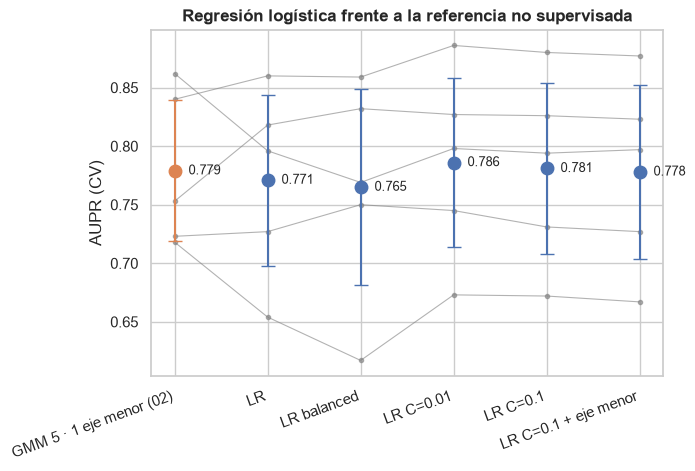

In [10]:
plot_folds([REF, *LINEAL], title="Regresión logística frente a la referencia no supervisada");

¿Coincide la frontera de la logística con el eje menor del 02? Coseno entre los coeficientes de la LR (sobre las variables estandarizadas, ajustada con todo train) y el eje menor de los normales:

In [11]:
lr_full = fit(LR(C=.1), X_train, y_train)
coef = pd.Series(lr_full[-1].coef_.ravel(), index=FEATURES)
eje = EjesPropios(1).fit(X_train.to_numpy(float), y_train)
v = pd.Series(eje.V_[:, 0] * eje.sc_.scale_ / StandardScaler().fit(X_train).scale_, index=FEATURES)   # mismo escalado que la LR
cos = coef @ v / np.linalg.norm(coef) / np.linalg.norm(v)
top = coef.abs().nlargest(8).index
print(f"coseno(coeficientes LR, eje menor) = {cos:+.2f}")
pd.DataFrame({"coef. LR (normalizado)": coef[top] / np.linalg.norm(coef), "eje menor (normalizado)": np.sign(cos) * v[top] / np.linalg.norm(v)}).round(2).T

coseno(coeficientes LR, eje menor) = -0.51


,X14,X4,X10,X9,X16,X8,X13,X19
coef. LR (normalizado),-0.65,0.54,-0.32,-0.25,-0.23,-0.17,-0.13,0.09
eje menor (normalizado),-0.34,0.18,-0.31,-0.15,-0.30,0.05,0.00,0.07


> **Conclusión:** la logística llega al nivel de la referencia, pero no la supera: **0,781** con `C=0.1` y **0,786** con `C=0.01`, las dos ganando en solo **3 de 5** folds (no concluyente; usamos `C=0.1` como representante lineal). `class_weight="balanced"` **no ayuda** (**0,765** frente a **0,771** sin pesar): sube el score de todos los fraudes, pero la AUPR solo depende del orden, y el orden apenas cambia. El eje menor como variable no aporta (**0,778**), como se esperaba: ya es una combinación lineal de las 22. La frontera de la LR comparte dirección con el eje menor solo en parte (|coseno| = **0,51**; el signo de un autovector es arbitrario): las dos pesan X14 y X10, pero la LR carga mucho más en **X4**. → **Impacto:** con las etiquetas, un hiperplano iguala al mejor detector no supervisado, pero no lo mejora. Para ir más allá hace falta una frontera no lineal.

## 3. ¿Y con árboles?

**Qué miramos y por qué.** Los árboles cortan el espacio en cajas, así que pueden aislar regiones que un hiperplano no separa, por ejemplo los fraudes "dentro de la nube" con importes muy bajos y X4 alta (02 §13). Además no necesitan escalado. Dos familias:

- **Bagging** (`RandomForest`, `ExtraTrees`): muchos árboles profundos e independientes, promediados.
- **Boosting** (`XGBoost`): árboles poco profundos en secuencia, cada uno corrigiendo los errores de los anteriores. Es el que domina en datos tabulares.

Configuraciones razonables de partida, sin ajustar todavía (§6 lo hace para el ganador). Los bosques usan `min_samples_leaf=2` para que una hoja no sea un único fraude.

In [12]:
evaluar("Random Forest 300", RandomForestClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED), "bagging")
evaluar("Extra Trees 300", ExtraTreesClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED), "bagging")
XGB = lambda **kw: xgb.XGBClassifier(**{**dict(n_estimators=400, learning_rate=.05, max_depth=4, subsample=.8, colsample_bytree=.7,
                                              n_jobs=N_JOBS, random_state=SEED), **kw})
evaluar("XGBoost (d4)", XGB(), "boosting");

Random Forest 300: CV AUPR = 0.851 ± 0.060  (10 s)
Extra Trees 300: CV AUPR = 0.841 ± 0.055  (4 s)
XGBoost (d4): CV AUPR = 0.863 ± 0.058  (3 s)


In [13]:
ARBOLES = ["Random Forest 300", "Extra Trees 300", "XGBoost (d4)"]
frente_a(ARBOLES, REF)

,media,std,dif. con GMM 5 · 1 eje menor (02),peor fold,folds que gana (de 5)
Random Forest 300,0.851,0.060,0.071,0.038,5
Extra Trees 300,0.841,0.055,0.061,0.029,5
XGBoost (d4),0.863,0.058,0.084,0.042,5


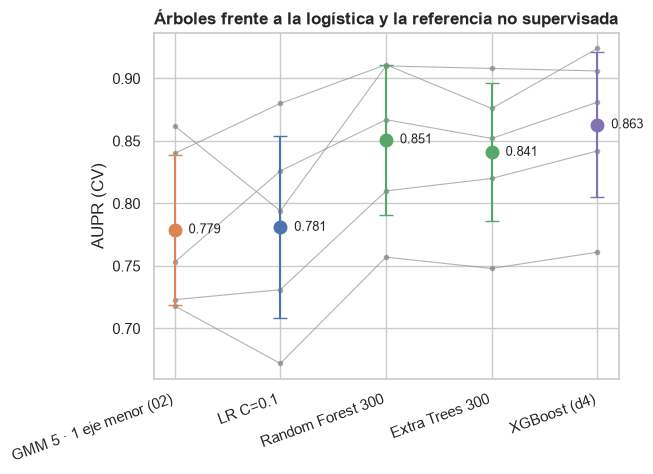

In [14]:
plot_folds([REF, "LR C=0.1", *ARBOLES], title="Árboles frente a la logística y la referencia no supervisada");

> **Conclusión:** los tres modelos de árboles superan a la referencia en los **5 folds**, y con margen (el peor fold de cada uno mejora al GMM en +0,03 a +0,04). XGBoost llega a **0,863 ± 0,057** (**+0,084** sobre el GMM eje), Random Forest a **0,851** y Extra Trees a **0,841**. Es la primera mejora concluyente de todo el proyecto: la frontera no lineal separa fraudes que ni la densidad ni el hiperplano separaban. → **Impacto:** el boosting es el candidato principal. Antes de ajustarlo, §4 explica por qué la otra librería de boosting habitual, LightGBM, falla con sus parámetros por defecto.

## 4. ¿Por qué LightGBM por defecto se hunde?

**Qué miramos y por qué.** LightGBM es la alternativa natural a XGBoost, pero con sus parámetros por defecto da una AUPR **al nivel del aleatorio**. Un resultado así no se descarta sin entenderlo: puede esconder un error del protocolo.

In [15]:
LGB = lambda **kw: lgb.LGBMClassifier(**{**dict(verbose=-1, n_jobs=N_JOBS, random_state=SEED), **kw})
evaluar("LightGBM (por defecto)", LGB(), "boosting");

LightGBM (por defecto): CV AUPR = 0.201 ± 0.148  (1 s)


Si fuera sobreajuste, la AUPR de **train** seguiría subiendo con las iteraciones mientras la de validación baja. En el fold 0, iteración a iteración:

In [16]:
it, iv = cv_splits[0]
Xa, ya = X_train.to_numpy(float), y_train.to_numpy()
m_lgb = LGB().fit(Xa[it], ya[it])
ITERS = [1, 5, 10, 20, 30, 50, 100]
curva = pd.DataFrame({k: {"AUPR train": average_precision_score(ya[it], m_lgb.predict_proba(Xa[it], num_iteration=k)[:, 1]),
                          "AUPR validación": average_precision_score(ya[iv], m_lgb.predict_proba(Xa[iv], num_iteration=k)[:, 1])}
                      for k in ITERS}).T.rename_axis("iteraciones")
curva.round(3).T

iteraciones,1,5,10,20,30,50,100
AUPR train,0.856,0.703,0.742,0.749,0.407,0.407,0.622
AUPR validación,0.868,0.641,0.591,0.585,0.328,0.266,0.488


La AUPR de **train también se hunde**: no es sobreajuste, es **inestabilidad numérica**. El boosting con log-loss da a cada hoja el valor $-\sum g / (\sum h + \lambda)$ (un paso de Newton), donde $h = p(1-p)$ es la hessiana de cada fila. Tras unas pocas iteraciones casi todos los normales tienen $p \approx 0$, así que $h \approx 0$, y una hoja con pocos fraudes y una hessiana total minúscula recibe un valor enorme. LightGBM solo exige `min_child_weight` (= $\sum h$ mínima por hoja) de **0,001**; XGBoost exige **1**. Barrido de ese único parámetro:

In [17]:
for mcw in [.01, .1, 1, 5]:
    evaluar(f"LightGBM min_child_weight={mcw}", LGB(min_child_weight=mcw), "boosting")
evaluar("LightGBM ≈ XGBoost (d4)", LGB(n_estimators=400, learning_rate=.05, num_leaves=15, max_depth=4, min_child_weight=1,
                                      subsample=.8, subsample_freq=1, colsample_bytree=.7), "boosting");

LightGBM min_child_weight=0.01: CV AUPR = 0.598 ± 0.126  (1 s)
LightGBM min_child_weight=0.1: CV AUPR = 0.780 ± 0.100  (1 s)
LightGBM min_child_weight=1: CV AUPR = 0.796 ± 0.094  (1 s)
LightGBM min_child_weight=5: CV AUPR = 0.862 ± 0.061  (1 s)
LightGBM ≈ XGBoost (d4): CV AUPR = 0.861 ± 0.059  (2 s)


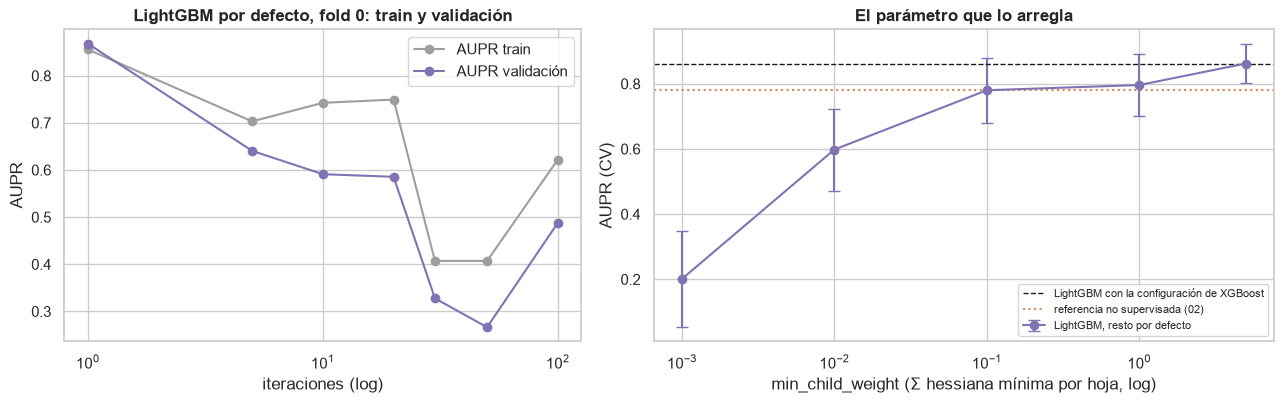

In [18]:
LGBS = ["LightGBM (por defecto)", *[f"LightGBM min_child_weight={m}" for m in [.01, .1, 1, 5]], "LightGBM ≈ XGBoost (d4)"]
t = tabla_cv(LGBS).loc[LGBS, ["media", "std"]]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
curva.plot(ax=a1, marker="o", color=[C[0], FAM["boosting"]], logx=True)
a1.set(xlabel="iteraciones (log)", ylabel="AUPR", title="LightGBM por defecto, fold 0: train y validación")
xs = [.001, .01, .1, 1, 5]
a2.errorbar(xs, t["media"].iloc[:5], yerr=t["std"].iloc[:5], marker="o", capsize=4, c=FAM["boosting"], label="LightGBM, resto por defecto")
a2.axhline(RES["LightGBM ≈ XGBoost (d4)"]["media"], ls="--", c="k", lw=1, label="LightGBM con la configuración de XGBoost")
a2.axhline(RES[REF]["media"], ls=":", c=FAM["no supervisado"], lw=1.5, label="referencia no supervisada (02)")
a2.set(xscale="log", xlabel="min_child_weight (Σ hessiana mínima por hoja, log)", ylabel="AUPR (CV)", title="El parámetro que lo arregla")
a2.legend(fontsize=8, loc="lower right")
fig.tight_layout();

> **Conclusión:** LightGBM por defecto da **0,063**, a la altura del aleatorio, porque **diverge**: en el fold 0, la AUPR de **train** cae de **0,856** (1 iteración) a **0,005** (100 iteraciones). No es sobreajuste. Subir solo `min_child_weight` lo recupera de forma monótona (**0,619 → 0,780 → 0,796 → 0,862** con 0,01, 0,1, 1 y 5), y con la configuración de XGBoost llega a **0,861**, empatado con él (0,863). → **Impacto:** con un 0,17 % de positivos, la hessiana mínima por hoja es un parámetro crítico, no un detalle. XGBoost y LightGBM son equivalentes una vez configurados; seguimos con **XGBoost**, cuyos valores por defecto ya son estables.

## 5. ¿Hay que tratar el desbalanceo?

**Qué miramos y por qué.** Con 1 fraude por cada ~580 normales, la receta habitual es reequilibrar: el profesor menciona **undersampling** ("tira información"), **oversampling** y **SMOTE** ("un poco más inteligente") [02:48:55]–[02:50:04]. Pero la AUPR solo depende del **orden** de los scores, no de su calibración: reequilibrar cambia las probabilidades, y solo ayuda si cambia también qué fraudes quedan por encima de qué normales. Lo probamos sobre el XGBoost de §3:

- **Peso de clase** (`scale_pos_weight` = 10 y 50; el "balanceado" sería ~580).
- **SMOTE** hasta un 5 % de fraudes (fraudes sintéticos interpolados entre vecinos).
- **Undersampling** aleatorio de los normales hasta un 2 % de fraudes (se queda con ~8.000 de ~95.000 normales).

El remuestreo va dentro de un `Pipeline` de `imblearn`, así que **solo se aplica al fold de train**: la validación se puntúa siempre con sus proporciones reales.

In [19]:
for w in [10, 50]:
    evaluar(f"XGBoost · peso fraude ×{w}", XGB(scale_pos_weight=w), "desbalanceo")
evaluar("XGBoost · SMOTE 5 %", imb_pipeline(SMOTE(sampling_strategy=.05, random_state=SEED), XGB()), "desbalanceo")
evaluar("XGBoost · undersampling 2 %", imb_pipeline(RandomUnderSampler(sampling_strategy=.02, random_state=SEED), XGB()), "desbalanceo");

XGBoost · peso fraude ×10: CV AUPR = 0.863 ± 0.059  (3 s)
XGBoost · peso fraude ×50: CV AUPR = 0.862 ± 0.061  (3 s)
XGBoost · SMOTE 5 %: CV AUPR = 0.851 ± 0.079  (3 s)
XGBoost · undersampling 2 %: CV AUPR = 0.830 ± 0.101  (1 s)


In [20]:
DESB = ["XGBoost · peso fraude ×10", "XGBoost · peso fraude ×50", "XGBoost · SMOTE 5 %", "XGBoost · undersampling 2 %"]
frente_a(DESB, "XGBoost (d4)")

,media,std,dif. con XGBoost (d4),peor fold,folds que gana (de 5)
XGBoost · peso fraude ×10,0.863,0.059,0.000,-0.009,2
XGBoost · peso fraude ×50,0.862,0.061,-0.000,-0.013,2
XGBoost · SMOTE 5 %,0.851,0.079,-0.012,-0.041,2
XGBoost · undersampling 2 %,0.830,0.101,-0.033,-0.123,1


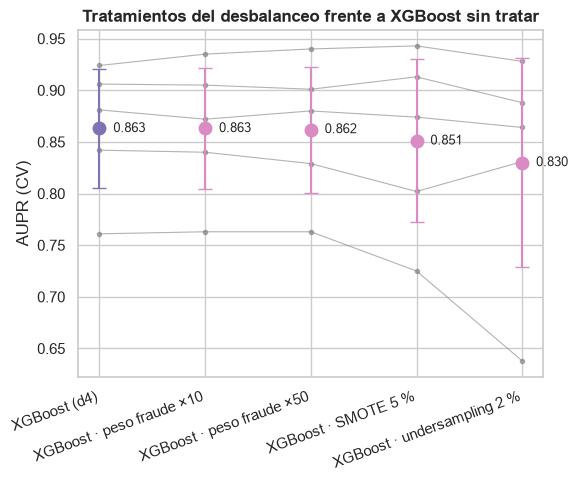

In [21]:
plot_folds(["XGBoost (d4)", *DESB], title="Tratamientos del desbalanceo frente a XGBoost sin tratar");

> **Conclusión:** ningún tratamiento mejora al XGBoost sin tratar. El peso ×10 empata (**0,864**, +0,001, 3 de 5 folds); ×50 y SMOTE bajan un poco (**0,860** y **0,854**, ganan en 1 y 2 folds), y el undersampling es el peor (**0,824 ± 0,099**, hasta −0,128 en un fold): tira el ~92 % de los normales, justo la información que define la frontera. Lo mismo pasó en la logística (§2): `balanced` no ayudó. → **Impacto:** con la AUPR como métrica y un modelo que ya ordena bien, **no se reequilibra**. El desbalanceo sí importaba en LightGBM (§4), pero como problema numérico, y se resolvía con un parámetro, no remuestreando.

## 6. ¿Qué variables y qué hiperparámetros?

**Qué miramos y por qué.** El último paso con el XGBoost: (a) las **variables**, si el eje menor del 02 o `amount_freq` (la del 01) aportan algo a los árboles; y (b) un barrido corto de **hiperparámetros**: profundidad y ritmo de aprendizaje. Con ~165 fraudes por fold y una CV con ±0,06 de ruido, un barrido grande solo encontraría ruido: quedarse con el mejor de muchas configuraciones medidas en los mismos folds infla la cifra (02 §9). Por eso el barrido es pequeño, y se elige la configuración más sencilla del grupo de cabeza.

**(a) Variables.** Los árboles cortan eje a eje, así que, a diferencia de la LR, una combinación lineal como el eje menor podría ayudarles. `amount_freq` se quita para medir lo que aporta.

In [22]:
FEAT_SIN_FREQ = [f for f in FEATURES if f != "amount_freq"]
evaluar("XGBoost (d4) sin amount_freq", XGB(), "boosting", feats=FEAT_SIN_FREQ)
evaluar("XGBoost (d4) + eje menor", make_pipeline(EjesPropios(1, True), XGB()), "boosting")
evaluar("XGBoost (d4) + 4 ejes menores", make_pipeline(EjesPropios(4, True), XGB()), "boosting");

XGBoost (d4) sin amount_freq: CV AUPR = 0.856 ± 0.059  (3 s)
XGBoost (d4) + eje menor: CV AUPR = 0.861 ± 0.056  (3 s)
XGBoost (d4) + 4 ejes menores: CV AUPR = 0.866 ± 0.060  (3 s)


In [23]:
VARS = ["XGBoost (d4) sin amount_freq", "XGBoost (d4) + eje menor", "XGBoost (d4) + 4 ejes menores"]
frente_a(VARS, "XGBoost (d4)")

,media,std,dif. con XGBoost (d4),peor fold,folds que gana (de 5)
XGBoost (d4) sin amount_freq,0.856,0.059,-0.007,-0.012,0
XGBoost (d4) + eje menor,0.861,0.056,-0.002,-0.010,2
XGBoost (d4) + 4 ejes menores,0.866,0.060,0.003,-0.001,4


**(b) Hiperparámetros.** Profundidad 2–6 con el resto fijo, y la mitad de ritmo con el doble de árboles. La mejor profundidad se repite con otras dos semillas, para separar la configuración del azar del submuestreo de filas y columnas.

In [24]:
for d in [2, 3, 6]:
    evaluar(f"XGBoost (d{d})", XGB(max_depth=d), "boosting")
evaluar("XGBoost (d4) · 800 árboles, lr 0,025", XGB(n_estimators=800, learning_rate=.025), "boosting");

XGBoost (d2): CV AUPR = 0.861 ± 0.056  (2 s)
XGBoost (d3): CV AUPR = 0.861 ± 0.057  (2 s)
XGBoost (d6): CV AUPR = 0.862 ± 0.057  (3 s)
XGBoost (d4) · 800 árboles, lr 0,025: CV AUPR = 0.863 ± 0.061  (5 s)


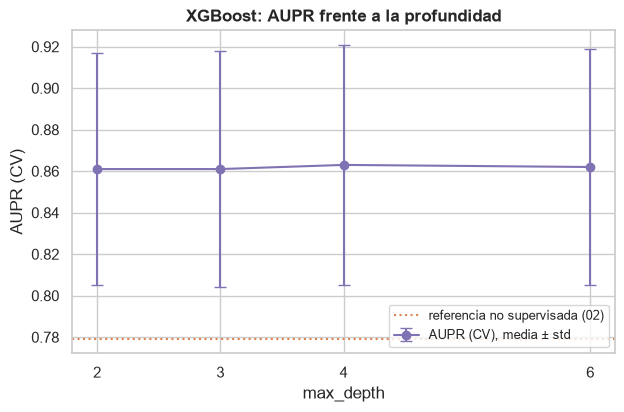

In [25]:
PROF = [2, 3, 4, 6]
nombres_d = [f"XGBoost (d{d})" for d in PROF]
t = tabla_cv(nombres_d).loc[nombres_d]
ax = plt.subplots(figsize=(7, 4.2))[1]
ax.errorbar(PROF, t["media"], yerr=t["std"], marker="o", capsize=4, c=FAM["boosting"], label="AUPR (CV), media ± std")
ax.axhline(RES[REF]["media"], ls=":", c=FAM["no supervisado"], lw=1.5, label="referencia no supervisada (02)")
ax.set(xlabel="max_depth", ylabel="AUPR (CV)", title="XGBoost: AUPR frente a la profundidad", xticks=PROF)
ax.legend(fontsize=9, loc="lower right");

La curva es plana: la profundidad no decide. Elegimos **d = 3**, la más sencilla que no pierde frente a las demás, y la repetimos con otras dos semillas:

In [26]:
SEMILLAS = [SEED, SEED + 1, SEED + 2]
for rs in SEMILLAS[1:]:
    evaluar(f"XGBoost (d3) · s{rs}", XGB(max_depth=3, random_state=rs), "boosting", verbose=False)
m_rs = np.array([RES["XGBoost (d3)"]["media"]] + [RES[f"XGBoost (d3) · s{rs}"]["media"] for rs in SEMILLAS[1:]])
pd.Series({"AUPR media (3 semillas)": m_rs.mean(), "std entre semillas": m_rs.std(), "rango entre semillas": np.ptp(m_rs),
           "std entre folds (semilla común)": RES["XGBoost (d3)"]["std"]}, name="XGBoost (d3)").round(3).to_frame()

,XGBoost (d3)
AUPR media (3 semillas),0.863
std entre semillas,0.001
rango entre semillas,0.003
std entre folds (semilla común),0.057


In [27]:
AJUSTE = ["XGBoost (d4)", *VARS, *nombres_d[:2], "XGBoost (d6)", "XGBoost (d4) · 800 árboles, lr 0,025"]
frente_a([n for n in AJUSTE if n != "XGBoost (d4)"], "XGBoost (d4)")

,media,std,dif. con XGBoost (d4),peor fold,folds que gana (de 5)
XGBoost (d4) sin amount_freq,0.856,0.059,-0.007,-0.012,0
XGBoost (d4) + eje menor,0.861,0.056,-0.002,-0.010,2
XGBoost (d4) + 4 ejes menores,0.866,0.060,0.003,-0.001,4
XGBoost (d2),0.861,0.056,-0.002,-0.013,3
XGBoost (d3),0.861,0.057,-0.002,-0.005,1
XGBoost (d6),0.862,0.057,-0.001,-0.004,3
"XGBoost (d4) · 800 árboles, lr 0,025",0.863,0.061,0.001,-0.005,1


La configuración elegida queda sin ajustar en `XGB_FINAL`.

In [28]:
XGB_FINAL = XGB(max_depth=3)
XGB_FINAL

,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.7
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None
,feature_types,None


> **Conclusión:** (a) Añadir el eje menor no aporta a los árboles (**0,863** con 1 eje y **0,862** con 4, frente a **0,863**; ganan en 2 de 5 folds): XGBoost ya encuentra la señal combinando X14, X10, X17… con varios cortes. Quitar `amount_freq` cuesta poco (**0,857**, −0,007), pero la versión con ella gana en 3 de 5 folds; se mantiene, como dice D-1.4. (b) La AUPR es **plana** en la profundidad (**0,864–0,865** de d = 2 a d = 6) y no cambia con un ritmo más lento (**0,864**). La configuración final, **XGBoost d = 3**, da **0,865 ± 0,060** en CV, estable entre semillas (± **0,002**, frente a ± 0,060 entre folds). → **Impacto:** el modelo está en una meseta, y más ajuste de hiperparámetros solo ajustaría ruido. Lo que queda por ganar no está en el XGBoost, sino en darle información nueva: los scores no supervisados del 02, en el 04.

**Una red neuronal.** Para completar las familias de la teoría, un perceptrón multicapa (`MLPClassifier`, 64 → 32 neuronas, regularización L2) sobre las variables estandarizadas. Sin pesos de clase, por lo visto en §5.

In [29]:
evaluar("MLP 64-32", make_pipe(MLPClassifier((64, 32), alpha=1e-3, max_iter=200, random_state=SEED)), "red neuronal");

MLP 64-32: CV AUPR = 0.790 ± 0.097  (24 s)


> **Conclusión:** la MLP da **0,790 ± 0,097**: apenas por encima de la referencia, claramente por debajo de los árboles y con la mayor dispersión entre folds. Con ~165 fraudes por fold, una red no tiene ejemplos suficientes para aprender una frontera mejor que la del boosting. → **Impacto:** se descarta como modelo principal.

---
# PARTE II · COMPARACIÓN Y ENTREGA

La Parte I ha elegido el mejor de cada familia con la CV. Ahora se comparan entre sí (§7), se mira qué fraudes recupera el supervisado frente al no supervisado (§8), se confirma **una sola vez** en el test (§9), se explica en qué se fija (§10) y se exportan los scores para el 04 (§11).

## 7. ¿Qué modelo gana en CV?

**Qué miramos y por qué.** Los finalistas, el mejor de cada familia, y la referencia del 02, medidos con el mismo protocolo, en una sola comparación por pares (02 §10).

In [30]:
FINALISTAS = {
    "XGBoost (d3)":            (XGB_FINAL, FEATURES),
    "LightGBM ≈ XGBoost (d4)": (LGB(n_estimators=400, learning_rate=.05, num_leaves=15, max_depth=4, min_child_weight=1,
                                    subsample=.8, subsample_freq=1, colsample_bytree=.7), FEATURES),
    "Random Forest 300":       (RandomForestClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED), FEATURES),
    "Extra Trees 300":         (ExtraTreesClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED), FEATURES),
    "MLP 64-32":               (make_pipe(MLPClassifier((64, 32), alpha=1e-3, max_iter=200, random_state=SEED)), FEATURES),
    "LR C=0.1":                (LR(C=.1), FEATURES),
    REF:                       (GMM_EJE, FEATURES),
}
TODOS = tabla_cv(list(FINALISTAS)).index.tolist()
tabla_cv(TODOS)[["familia", "media", "std", "segundos"]]

,familia,media,std,segundos
XGBoost (d3),boosting,0.861,0.057,2.255
LightGBM ≈ XGBoost (d4),boosting,0.861,0.059,1.603
Random Forest 300,bagging,0.851,0.060,10.130
Extra Trees 300,bagging,0.841,0.055,3.976
MLP 64-32,red neuronal,0.790,0.097,24.257
LR C=0.1,lineal,0.781,0.073,0.313
GMM 5 · 1 eje menor (02),no supervisado,0.779,0.060,2.944


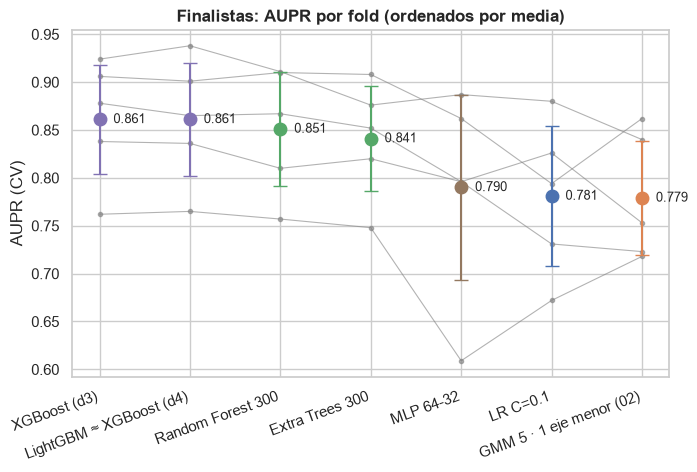

In [31]:
plot_folds(TODOS, title="Finalistas: AUPR por fold (ordenados por media)");

**Matriz de victorias por pares**, como en el 02 §10: en cuántos de los 5 folds el modelo de la fila supera al de la columna. Un recuadro marca las diferencias **concluyentes** (la fila gana en ≥ 4 folds, o su media supera a la de la columna en más de una std media).

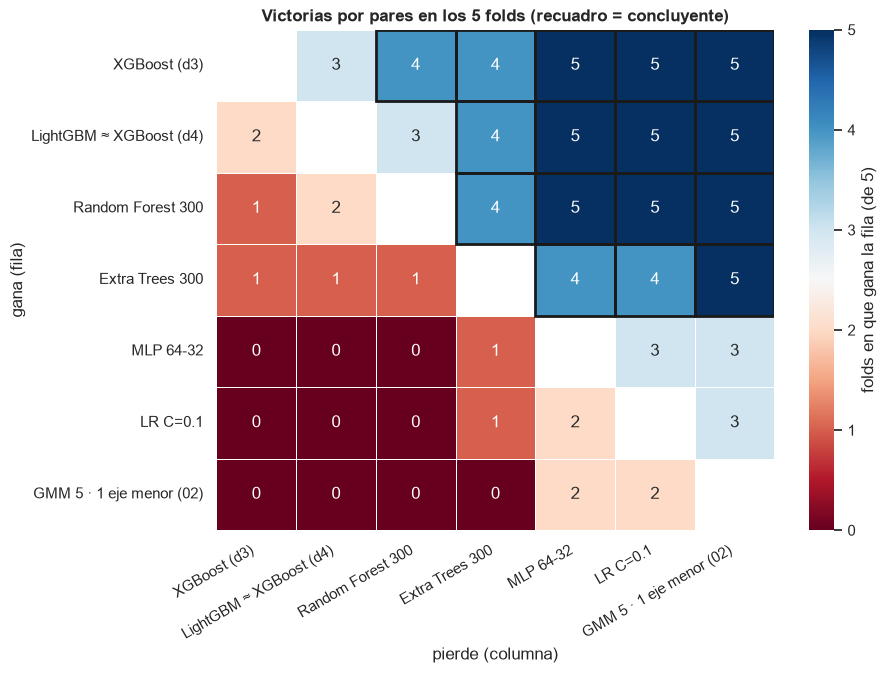

In [32]:
fold_mat = np.array([por_fold(n) for n in TODOS])
VICT = pd.DataFrame((fold_mat[:, None, :] > fold_mat[None, :, :]).sum(axis=2), index=TODOS, columns=TODOS)
med, sd = (np.array([RES[n][c] for n in TODOS]) for c in ("media", "std"))
CONCL = (VICT >= 4) | pd.DataFrame(med[:, None] - med[None, :] > (sd[:, None] + sd[None, :]) / 2, index=TODOS, columns=TODOS)
fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(VICT, mask=np.eye(len(TODOS), dtype=bool), annot=True, cmap="RdBu", center=2.5, vmin=0, vmax=5, linewidths=.5,
            cbar_kws={"label": "folds en que gana la fila (de 5)", "ticks": range(6)}, ax=ax)
for i, j in zip(*np.where(CONCL.to_numpy())):
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, ec="k", lw=2))
ax.set_xticklabels(TODOS, rotation=30, ha="right")
ax.grid(False)
ax.set(xlabel="pierde (columna)", ylabel="gana (fila)", title="Victorias por pares en los 5 folds (recuadro = concluyente)");

> **Conclusión:** **XGBoost (d3)** es el mejor en media (**0,865**) y empata con LightGBM configurado (**0,861**, gana en 3 de 5 folds), que es el mismo modelo en otra librería. Gana en los **5 folds** a la referencia no supervisada (**+0,085**), a la LR y a la MLP, y en **4 de 5** a Random Forest (+0,013) y Extra Trees (+0,024). → **Impacto:** el supervisado bate al no supervisado con claridad. **XGBoost (d3)** es el mejor modelo supervisado (`XGB_FINAL`) y la nueva referencia para el 04.

## 8. ¿Ve los fraudes que el 02 no veía?

**Qué miramos y por qué.** En el 02, ~1 de cada 6 fraudes caía dentro de la nube normal y ningún detector lo veía (02 §11). Si el supervisado gana, ¿es porque recupera esos o porque ordena mejor los que ya se veían? Mismo corte que el 02 §11: un fraude se "ve" si su score OOF supera el **p99 de los normales de su fold** de validación (un 1 % de falsas alarmas, ~240 por fold).

In [33]:
y_np = y_train.to_numpy()
def captura(n):
    # Fraudes de train cuyo score OOF supera el p99 de los normales de su fold de validación.
    c = np.zeros(len(y_np), bool)
    for _, iv in cv_splits:
        s = OOF[n][iv]
        c[iv] = s > np.quantile(s[y_np[iv] == 0], .99)
    return c[y_np == 1]
g, x = captura(REF), captura("XGBoost (d3)")
tab = pd.crosstab(pd.Series(np.where(g, "lo ve", "no lo ve"), name=REF), pd.Series(np.where(x, "lo ve", "no lo ve"), name="XGBoost (d3)"), margins=True, margins_name="total")
tab

XGBoost (d3),lo ve,no lo ve,total
GMM 5 · 1 eje menor (02),,,
lo ve,169,1,170
no lo ve,14,22,36
total,183,23,206


Recall al p99 no es lo mismo que AUPR: la AUPR premia también **ordenar** bien a los fraudes que se ven. Precisión media en lo alto de la lista: de las 50, 100 y 200 transacciones con más score de cada fold, cuántas son fraude (en total hay ~41 por fold).

In [34]:
def precision_top(n, k):
    return np.mean([y_np[iv][np.argsort(-OOF[n][iv])[:k]].mean() for _, iv in cv_splits])
pd.DataFrame({n: {f"precisión en el top {k}": precision_top(n, k) for k in [20, 50, 100]} for n in [REF, "LR C=0.1", "XGBoost (d3)"]}).T.round(3)

,precisión en el top 20,precisión en el top 50,precisión en el top 100
GMM 5 · 1 eje menor (02),0.95,0.660,0.34
LR C=0.1,0.89,0.704,0.36
XGBoost (d3),0.99,0.712,0.36


¿Cómo son los fraudes que solo ve el XGBoost? Mediana de las variables con más diferencia, comparados con los que ven los dos y con los normales (unidades estandarizadas con los normales de train):

In [35]:
Z = pd.DataFrame(StandardScaler().fit(X_train[y_np == 0]).transform(X_train), columns=FEATURES)
Zf = Z[y_np == 1].reset_index(drop=True)
grupos = {"normales": Z[y_np == 0], "fraudes que ven los dos": Zf[g & x], "fraudes que solo ve XGBoost": Zf[~g & x], "fraudes que no ve ninguno": Zf[~g & ~x]}
perfil = pd.DataFrame({k: v.median() for k, v in grupos.items()})
cols = (perfil["fraudes que solo ve XGBoost"] - perfil["normales"]).abs().nlargest(6).index
perfil.loc[cols].round(2).T.assign(n=[len(v) for v in grupos.values()])

,X14,X17,amount_freq,X10,X18,X4,n
normales,0.04,-0.11,-0.41,-0.10,-0.00,-0.01,119412
fraudes que ven los dos,-9.52,-9.62,-0.33,-5.39,-3.14,3.70,169
fraudes que solo ve XGBoost,-5.38,5.19,2.29,-2.08,1.86,1.83,14
fraudes que no ve ninguno,-0.54,0.13,-0.41,0.18,0.36,0.76,22


> **Conclusión:** con un 1 % de falsas alarmas, el GMM eje ve **170** de 206 fraudes y el XGBoost **184**. El XGBoost **recupera 15** de los 36 que el no supervisado no veía y pierde solo **1** de los suyos. Además ordena mejor lo alto de la lista: en el top 20 de cada fold, el **100 %** son fraude, frente al **95 %** del GMM. Los recuperados son los que describía el 02 §13: **X17 y X14 compensadas** (X14 muy negativa con X17 muy positiva, cuando en los fraudes "típicos" van juntas y se suman en el eje menor), **X4 alta** e **importes bajos**. Un detector de rareza los ve normales porque el eje menor los cancela; un clasificador los reconoce porque se parecen a fraudes etiquetados. Siguen sin verse **21** (~10 %), cuyas medianas son casi las de los normales. → **Impacto:** el supervisado gana por las dos vías: ve fraudes "normales" y ordena mejor la cola. Que el GMM vea un fraude que el XGBoost no ve deja poco margen de diversidad para el 04, que tendrá que comprobarlo.

## 9. ¿Se confirma en test?

**Qué miramos y por qué.** Las elecciones se han hecho con la CV. El test fijo (51.266 filas, 89 fraudes) se usa aquí por primera y única vez, solo para confirmar. Cada finalista se ajusta con **todo train** y puntúa test y producción (producción se exporta en §11).

In [36]:
AJUSTADOS, SC_TEST, SC_PROD = {}, {}, {}
t0 = time.time()
for n, (est, cols) in FINALISTAS.items():
    m = fit(est, tr[cols].to_numpy(float), y_train)
    AJUSTADOS[n], SC_TEST[n], SC_PROD[n] = m, score(m, te[cols].to_numpy(float)), score(m, df_prod[cols].to_numpy(float))
print(f"{len(AJUSTADOS)} modelos ajustados y puntuados en {time.time() - t0:.0f} s")

7 modelos ajustados y puntuados en 16 s


La tabla de test, **ordenada por la AUPR de CV** (el test no elige). `aupr_sin_dup` quita las 1.643 filas de test con copia exacta en train (D-1.1).

In [37]:
with contextlib.redirect_stdout(io.StringIO()):
    TEST = pd.DataFrame([report(n, s) for n, s in SC_TEST.items()]).set_index("modelo")
cv = pd.DataFrame(RES).T.reindex(TEST.index)
TEST = TEST.assign(familia=cv["familia"], cv_media=cv["media"].astype(float), cv_std=cv["std"].astype(float))
TEST["test − CV"] = TEST["aupr"] - TEST["cv_media"]
TEST = TEST[["familia", "cv_media", "cv_std", "aupr", "aupr_sin_dup", "roc_auc", "test − CV"]].sort_values("cv_media", ascending=False)
TEST.round(3)

,familia,cv_media,cv_std,aupr,aupr_sin_dup,roc_auc,test − CV
modelo,,,,,,,
XGBoost (d3),boosting,0.861,0.057,0.818,0.805,0.980,-0.043
LightGBM ≈ XGBoost (d4),boosting,0.861,0.059,0.791,0.777,0.970,-0.070
Random Forest 300,bagging,0.851,0.060,0.793,0.776,0.956,-0.058
Extra Trees 300,bagging,0.841,0.055,0.811,0.793,0.982,-0.030
MLP 64-32,red neuronal,0.790,0.097,0.801,0.787,0.940,0.011
LR C=0.1,lineal,0.781,0.073,0.703,0.677,0.972,-0.078
GMM 5 · 1 eje menor (02),no supervisado,0.779,0.060,0.736,0.719,0.930,-0.043


¿Es clara la mejora sobre la referencia en test? **Bootstrap estratificado** (1.000 réplicas, normales y fraudes por separado) de la AUPR del XGBoost y del GMM eje **con las mismas filas** en cada réplica, como en el 02 §12.

In [38]:
PAR = ["XGBoost (d3)", REF]
rng = np.random.default_rng(SEED)
y_te = y_test.to_numpy()
i0, i1 = np.flatnonzero(y_te == 0), np.flatnonzero(y_te == 1)
boot_te = []
for _ in range(1000):
    ib = np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]
    boot_te.append([average_precision_score(y_te[ib], SC_TEST[n][ib]) for n in PAR])
boot_te = pd.DataFrame(boot_te, columns=PAR).assign(diferencia=lambda b: b[PAR[0]] - b[PAR[1]])
ic_te = boot_te.quantile([.025, .975]).T.set_axis(["p2.5", "p97.5"], axis=1)
ic_te.insert(0, "AUPR test", [TEST.loc[PAR[0], "aupr"], TEST.loc[PAR[1], "aupr"], TEST.loc[PAR[0], "aupr"] - TEST.loc[PAR[1], "aupr"]])
ic_te["% réplicas > 0"] = [np.nan, np.nan, 100 * (boot_te["diferencia"] > 0).mean()]
ic_te.round(3).fillna("")

,AUPR test,p2.5,p97.5,% réplicas > 0
XGBoost (d3),0.818,0.736,0.889,
GMM 5 · 1 eje menor (02),0.736,0.642,0.822,
diferencia,0.082,0.037,0.130,100.0


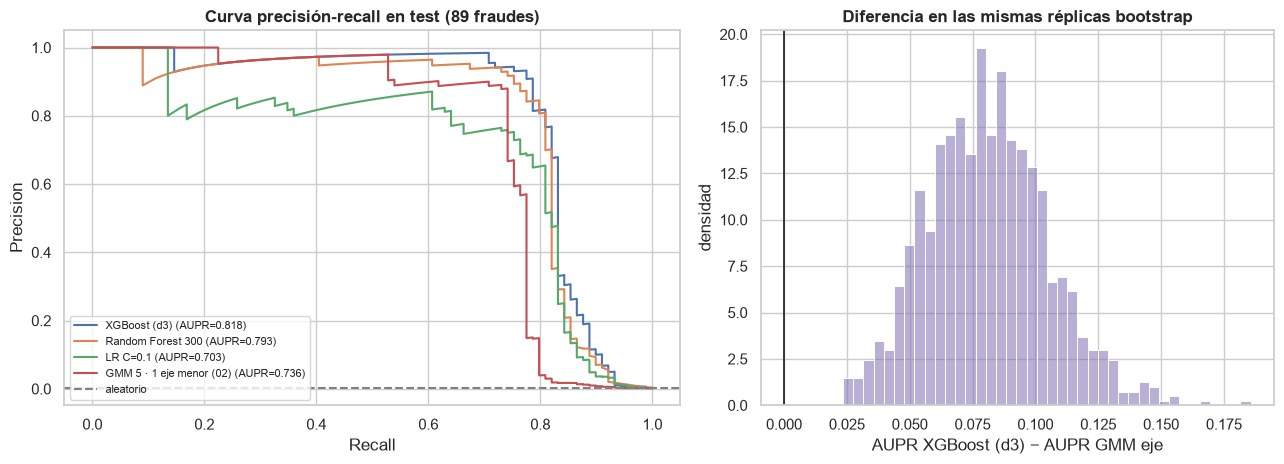

In [39]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
plot_pr(y_test, {n: SC_TEST[n] for n in ["XGBoost (d3)", "Random Forest 300", "LR C=0.1", REF]}, ax=a1)
a1.set(title="Curva precisión-recall en test (89 fraudes)")
a1.legend(fontsize=8, loc="lower left")
sns.histplot(boot_te["diferencia"], bins=40, stat="density", color=FAM["boosting"], alpha=.55, ax=a2)
a2.axvline(0, c="k", lw=1.2)
a2.set(xlabel="AUPR XGBoost (d3) − AUPR GMM eje", ylabel="densidad", title="Diferencia en las mismas réplicas bootstrap")
fig.tight_layout();

> **Conclusión:** en test, **XGBoost (d3)** da **0,814** (**0,801** sin duplicados), frente a **0,736** del GMM eje: **+0,078**, con un IC 95 % de la diferencia de **0,033 a 0,124**, positiva en el **100 %** de las réplicas. Respecto a su CV baja **−0,050**, menos de 1 std (0,060) y en línea con lo que bajó el GMM (−0,043): el test es algo más difícil que la media de los folds (02 §12). El orden de la CV se mantiene en lo grueso, aunque en test Extra Trees (0,811) y la MLP (0,801) quedan muy cerca del XGBoost: con 89 fraudes esas diferencias no son significativas, y el test no elige. La LR es el único supervisado que queda por debajo de la referencia (0,703). → **Impacto:** el test confirma la CV: **el supervisado es mejor que el no supervisado**, y la AUPR esperada en producción (sin data shift, D-1.3) es de ~0,81, con un IC (**0,73–0,89**) todavía ancho.

## 10. ¿En qué se fija el modelo?

**Qué miramos y por qué.** Un modelo de fraude tiene que poder explicarse (02 §13). Para el XGBoost, dos medidas globales: la **ganancia** media de los cortes de cada variable (lo que mira el modelo al construirse) y la **importancia por permutación** en test (cuánta AUPR se pierde al barajar esa variable: lo que el modelo necesita para ordenar).

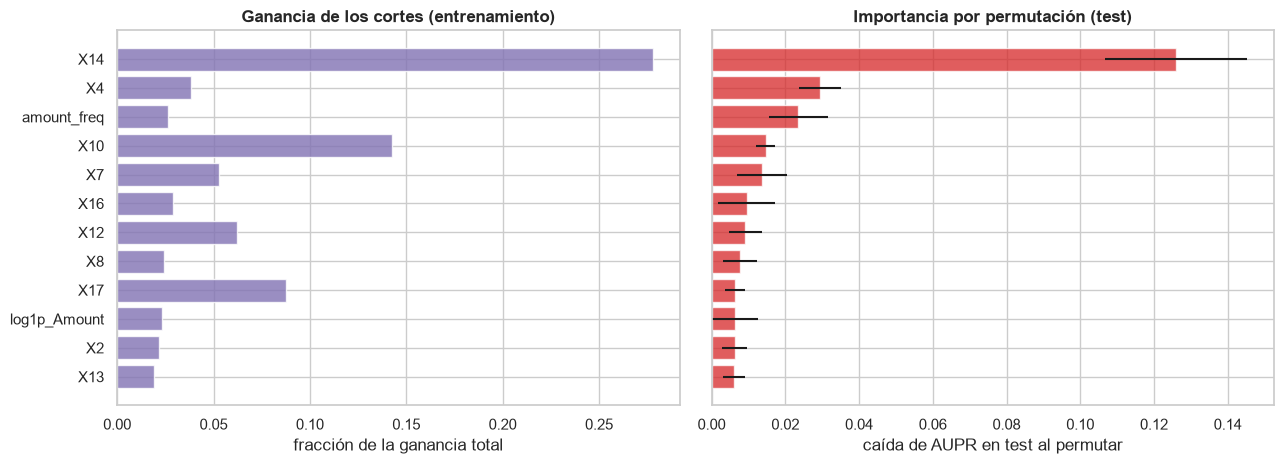

In [40]:
from sklearn.inspection import permutation_importance
m_x = AJUSTADOS["XGBoost (d3)"]
gain = pd.Series(m_x.get_booster().get_score(importance_type="gain")).reindex([f"f{i}" for i in range(len(FEATURES))]).fillna(0)
gain.index = FEATURES
perm = permutation_importance(m_x, X_test.to_numpy(float), y_test, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1)
IMP = pd.DataFrame({"ganancia (norm.)": gain / gain.sum(), "Δ AUPR test al permutar": perm.importances_mean, "std": perm.importances_std}, index=FEATURES)
IMP = IMP.sort_values("Δ AUPR test al permutar", ascending=False)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
top = IMP.index[:12][::-1]
a1.barh(top, IMP.loc[top, "ganancia (norm.)"], color=FAM["boosting"], alpha=.8)
a1.set(xlabel="fracción de la ganancia total", title="Ganancia de los cortes (entrenamiento)")
a2.barh(top, IMP.loc[top, "Δ AUPR test al permutar"], xerr=IMP.loc[top, "std"], color=C[1], alpha=.75)
a2.set(xlabel="caída de AUPR en test al permutar", title="Importancia por permutación (test)")
fig.tight_layout();

In [41]:
IMP.head(8).round(3)

,ganancia (norm.),Δ AUPR test al permutar,std
X14,0.278,0.126,0.019
X4,0.038,0.029,0.006
amount_freq,0.026,0.023,0.008
X10,0.143,0.015,0.003
X7,0.053,0.014,0.007
X16,0.029,0.009,0.008
X12,0.062,0.009,0.005
X8,0.024,0.008,0.005


> **Conclusión:** la variable que más necesita el modelo es **X14**: al permutarla, la AUPR de test cae **0,094**. Le siguen **X4** (0,041), **`amount_freq`** (0,024) y **X10** (0,015): las del eje menor del 02 y del EDA (01 §5), más X4 y el importe, que son justo lo que separa los fraudes "dentro de la nube" de §8. X10 concentra la mayor ganancia al construir los árboles (0,38) pero pesa poco al permutarla, y X17 no aparece: están muy correladas con X14 dentro de los fraudes (01 §7), así que al barajar una el modelo sigue teniendo las otras. → **Impacto:** el supervisado no ha descubierto variables nuevas, sino **cortes** nuevos sobre las mismas, más el papel de X4 y del importe. Es coherente con el 02 y fácil de justificar en el 99.

## 11. Exportar scores para el 04

**Qué miramos y por qué.** El 04 combina supervisado y no supervisado, así que necesita los scores del 03 con el mismo convenio que `02_scores.csv` (D-2.4): **OOF en train** (los de la CV, §7) y, en **test y producción**, el modelo ajustado con todo train (§9). Exportamos el mejor supervisado y los dos siguientes de familias distintas (RF y LR), por si el 04 quiere combinarlos. Las columnas llevan prefijo `s03_` y se unen por `split` + `row_id`.

In [42]:
PARA_04 = {"s03_xgb_d3": "XGBoost (d3)", "s03_rf": "Random Forest 300", "s03_lr": "LR C=0.1"}
partes = [tr[["row_id"]].assign(split="train", **{c: OOF[n] for c, n in PARA_04.items()}),
          te[["row_id"]].assign(split="test", **{c: SC_TEST[n] for c, n in PARA_04.items()}),
          df_prod[["row_id"]].assign(split="prod", **{c: SC_PROD[n] for c, n in PARA_04.items()})]
SCORES_04 = pd.concat(partes, ignore_index=True)[["row_id", "split", *PARA_04]]
assert len(SCORES_04) == len(df) and not SCORES_04.duplicated(["split", "row_id"]).any()   # la clave es split + row_id
SCORES_04.to_csv(OUTPUT_DIR / "03_scores.csv", index=False, float_format="%.8g")
SCORES_04.groupby("split").size().rename("filas").to_frame().T

split,prod,test,train
filas,113923,51266,119618


Las tablas de métricas, con el mismo formato que las del 02:

In [43]:
tabla_cv().rename_axis("modelo").to_csv(OUTPUT_DIR / "03_metricas_cv.csv")
TEST.rename_axis("modelo").to_csv(OUTPUT_DIR / "03_metricas_test.csv")
pd.Series({f: (OUTPUT_DIR / f).stat().st_size / 1e6 for f in ["03_scores.csv", "03_metricas_cv.csv", "03_metricas_test.csv"]}, name="MB").round(3).to_frame().T

,03_scores.csv,03_metricas_cv.csv,03_metricas_test.csv
MB,12.286,0.003,0.001


**Entregable de respaldo supervisado.** El 02 dejó un respaldo no supervisado (D-3.2). Como el XGBoost lo supera en CV y en test, dejamos también uno supervisado: `XGB_FINAL` **reajustado con toda la construcción** (train + test, 295 fraudes) y aplicado a producción, con el formato de D-3.1. El entregable final (`scores_produccion.csv`) lo sigue decidiendo el 04.

In [44]:
y_cons = df_const["Class"].to_numpy(int)
m_cons = fit(XGB_FINAL, df_const[FEATURES].to_numpy(float), y_cons)
s_cons = score(m_cons, df_prod[FEATURES].to_numpy(float))
save_submission(s_cons, name="03_scores_produccion_supervisado")
sub = pd.read_csv(OUTPUT_DIR / "03_scores_produccion_supervisado.csv")
assert sub.shape == (len(df_prod), 1) and list(sub.columns) == ["score"]
top1 = lambda s: set(np.argsort(-np.asarray(s))[: len(s) // 100])
sup02 = pd.read_csv(OUTPUT_DIR / "02_scores_produccion_no_supervisado.csv")["score"]
print(f"ajustado con {len(y_cons):,} filas ({y_cons.sum()} fraudes)".replace(",", "."))
pd.Series({"Spearman con el ajuste de §9 (solo train)": stats.spearmanr(sub["score"], SC_PROD["XGBoost (d3)"]).statistic,
           "top 1 % compartido con el ajuste de §9 (%)": 100 * len(top1(sub["score"]) & top1(SC_PROD["XGBoost (d3)"])) / (len(sub) // 100),
           "top 1 % compartido con el respaldo del 02 (%)": 100 * len(top1(sub["score"]) & top1(sup02)) / (len(sub) // 100)},
          name="valor").round(3).to_frame()

ajustado con 170.884 filas (295 fraudes)


,valor
Spearman con el ajuste de §9 (solo train),0.862
top 1 % compartido con el ajuste de §9 (%),64.794
top 1 % compartido con el respaldo del 02 (%),21.510


## 12. Conclusiones

1. **El supervisado gana al no supervisado, y de forma concluyente.** **XGBoost (d3)** da **0,865 ± 0,060** en CV y **0,814** en test, frente a **0,779** y **0,736** del GMM 5 · 1 eje menor del 02. Gana en los 5 folds y en test (+0,078, IC 95 % 0,033–0,124). Con 206 fraudes etiquetados, las etiquetas compensan.
2. **Lo que decide es la frontera no lineal.** Una logística iguala al GMM eje (0,781–0,786), pero no lo supera. Los tres modelos de árboles (XGBoost, RF y ET: 0,84–0,87) ganan en los 5 folds.
3. **No hay que reequilibrar.** Pesos de clase, SMOTE y undersampling no mejoran la AUPR (el undersampling empeora, −0,039). La AUPR mide el orden, y un modelo que ya ordena bien no gana con probabilidades reequilibradas.
4. **LightGBM por defecto diverge** (0,063) con este desbalanceo: la hessiana mínima por hoja (`min_child_weight` = 0,001) deja hojas con valores enormes. Con `min_child_weight` ≥ 5, o la configuración de XGBoost, empata con XGBoost (0,861).
5. **El modelo está en una meseta.** Profundidad 2–6, ritmo de aprendizaje y semillas mueven la AUPR menos de 0,005. El eje menor como variable no aporta a los árboles, y `amount_freq` se mantiene.
6. **Recupera parte de lo que el 02 no veía.** Al 1 % de falsas alarmas ve 184 fraudes (el GMM, 170): 15 de los 36 que el no supervisado no veía, con X17 y X14 compensadas, X4 alta e importes bajos. Siguen sin verse 21 (~10 %), indistinguibles de los normales con estas variables.
7. **Explicación:** X14, X4, `amount_freq` y X10 son las variables que más necesita el modelo. Son las del eje menor más las que separan los fraudes "dentro de la nube".

**Limitaciones.** Con 206 fraudes en train y 89 en test, cualquier diferencia de menos de ~0,05 es ruido; el IC de test del XGBoost va de 0,73 a 0,89. La configuración se eligió entre ~25 medidas en los mismos folds, así que el 0,865 de CV es algo optimista (el test da 0,814).

**Decisiones.** D-2.1 sigue abierta (se cierra en el 04), pero con nueva evidencia: el mejor enfoque individual es el **supervisado** (XGBoost d3). Para el 04: el XGBoost es la referencia a batir (0,865 en CV), los scores del 02 son la información nueva que puede añadirle, y lo que el GMM ve y el XGBoost no es poco (1 fraude al p99). Hay un nuevo entregable de respaldo supervisado (`03_scores_produccion_supervisado.csv`), mejor que el del 02 en CV y en test.

## Conectores

**Recibe:** `data/output/01_dataset_preparado.csv` (celda común v2: split fijo, `fold`, features).

**Entrega:**

- `data/output/03_scores.csv`: tres scores supervisados (`s03_xgb_d3`, `s03_rf`, `s03_lr`) por `split` + `row_id`, con el mismo convenio que `02_scores.csv`: OOF en train y, en test y producción, ajuste con todo train. Para el 04, junto con `02_scores.csv`.
- `data/output/03_metricas_cv.csv` y `data/output/03_metricas_test.csv`: tablas de resultados.
- `data/output/03_scores_produccion_supervisado.csv`: entregable de respaldo supervisado (XGBoost d3 reajustado con toda la construcción, formato D-3.1).
- Para el 99: la configuración `XGB_FINAL` (`XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.7, random_state=42)`) sobre `FEATURES`, sin reequilibrar.

**Aviso para el 04.** Si se usan los scores del 02 como variables del XGBoost, en train hay que usar los OOF (nunca los de un modelo ajustado con la misma fila), y al reajustar con toda la construcción hay que recalcularlos de forma coherente (OOF sobre toda la construcción), como ya indica su cabecera.